# Flood Occurrence Prediction – Sri Lanka
Random Forest vs XGBoost vs Voting vs Stacking

## 1. Setup

In [1]:
import warnings, pickle
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, roc_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

SEED = 42

## 2. Data

In [2]:
df = pd.read_csv("sri_lanka_flood_risk_dataset_25000.csv")
print(df.shape)
print(df.isnull().sum()[lambda s: s > 0])
df["flood_occurrence_current_event"].value_counts(normalize=True)

(25000, 32)
electricity                  789
reason_not_good_to_live    18172
dtype: int64


flood_occurrence_current_event
No     0.90112
Yes    0.09888
Name: proportion, dtype: float64

**Target:** `flood_occurrence_current_event` (Yes/No). Columns that leak the target or are identifiers are dropped.

In [3]:
target = "flood_occurrence_current_event"
leak = ["inundation_area_sqm", "flood_risk_score", "is_good_to_live", "reason_not_good_to_live"]
ids = ["record_id", "place_name", "generation_date", "is_synthetic"]

y = (df[target] == "Yes").astype(int)
X = df.drop(columns=[target] + leak + ids)

skewed = ["distance_to_river_m", "population_density_per_km2", "nearest_hospital_km", "nearest_evac_km"]
numeric = [c for c in X.select_dtypes("number").columns if c not in skewed]
categorical = X.select_dtypes(exclude="number").columns.tolist()
print(len(numeric) + len(skewed), "numeric |", len(categorical), "categorical")

15 numeric | 8 categorical


## 3. Preprocessing

In [4]:
pre = ColumnTransformer([
    ("num",  Pipeline([("imp", SimpleImputer(strategy="median")),
                       ("sc",  StandardScaler())]), numeric),
    ("skew", Pipeline([("imp", SimpleImputer(strategy="median")),
                       ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                       ("sc",  StandardScaler())]), skewed),
    ("cat",  Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                       ("oh",  OneHotEncoder(handle_unknown="ignore"))]), categorical),
])

## 4. Split (one sample held out for inference)

In [5]:
holdout = X.sample(1, random_state=SEED).index
X_new, y_new = X.loc[holdout], y.loc[holdout]
X_rest, y_rest = X.drop(holdout), y.drop(holdout)

X_train, X_test, y_train, y_test = train_test_split(
    X_rest, y_rest, test_size=0.2, stratify=y_rest, random_state=SEED)
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(X_train.shape, X_test.shape, f"scale_pos_weight = {spw:.2f}")

(19999, 23) (5000, 23) scale_pos_weight = 9.11


## 5. Hyperparameter tuning

In [6]:
def tune(model, grid):
    pipe = Pipeline([("pre", pre), ("clf", model)])
    s = RandomizedSearchCV(pipe, {f"clf__{k}": v for k, v in grid.items()}, n_iter=8, cv=3,
                           scoring="average_precision", random_state=SEED, n_jobs=1)
    s.fit(X_train, y_train)
    print(f"CV PR-AUC: {s.best_score_:.3f}")
    print({k.replace("clf__", ""): v for k, v in s.best_params_.items()})
    return s.best_estimator_.named_steps["clf"]

rf = tune(
    RandomForestClassifier(class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    {"n_estimators": [200, 300, 400], "max_depth": [6, 8, 10, 14],
     "min_samples_leaf": [3, 5, 10], "max_features": ["sqrt", 0.3, 0.5]})

CV PR-AUC: 0.583
{'n_estimators': 400, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}


In [7]:
xgb = tune(
    XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", tree_method="hist",
                  random_state=SEED, n_jobs=-1),
    {"n_estimators": [200, 400], "max_depth": [3, 4, 5, 6], "learning_rate": [0.03, 0.05, 0.1],
     "subsample": [0.7, 0.8, 0.9], "colsample_bytree": [0.6, 0.8],
     "min_child_weight": [1, 3, 5], "reg_lambda": [1, 5, 10]})

CV PR-AUC: 0.612
{'subsample': 0.8, 'reg_lambda': 10, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


## 6. Models

In [8]:
estimators = [("rf", clone(rf)), ("xgb", clone(xgb))]
models = {
    "Random Forest": rf,
    "XGBoost": xgb,
    "Soft Voting": VotingClassifier(estimators, voting="soft"),
    "Stacking": StackingClassifier(estimators, final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
                                   cv=3, stack_method="predict_proba"),
}
fitted = {n: Pipeline([("pre", pre), ("clf", m)]).fit(X_train, y_train) for n, m in models.items()}

## 7. Evaluation

In [9]:
rows = {}
for n, m in fitted.items():
    p = m.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    rows[n] = {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
               "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
               "F1": f1_score(y_test, pred)}
results = pd.DataFrame(rows).T.round(3)
results

,ROC-AUC,PR-AUC,Precision,Recall,F1
Random Forest,0.952,0.572,0.472,0.915,0.623
XGBoost,0.960,0.606,0.540,0.953,0.689
Soft Voting,0.960,0.597,0.535,0.964,0.688
Stacking,0.960,0.598,0.513,0.968,0.671


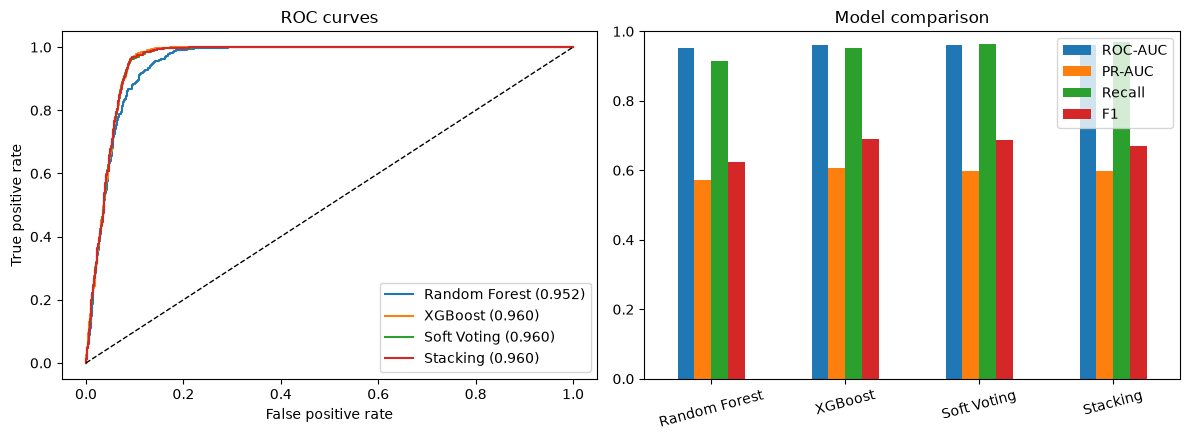

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for n, m in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    ax[0].plot(fpr, tpr, label=f"{n} ({rows[n]['ROC-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
ax[0].legend()
results[["ROC-AUC", "PR-AUC", "Recall", "F1"]].plot.bar(ax=ax[1], rot=15)
ax[1].set(title="Model comparison", ylim=(0, 1))
plt.tight_layout(); plt.show()

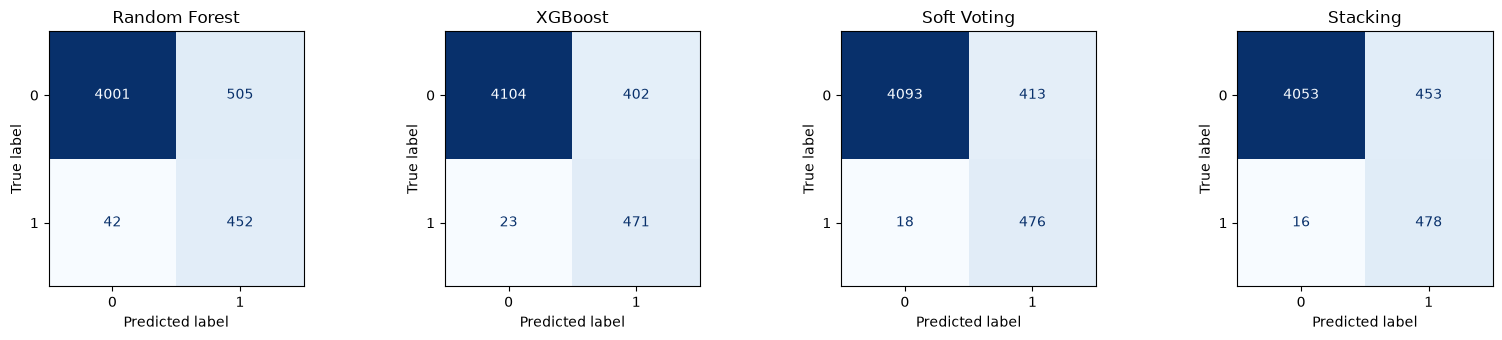

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, (n, m) in zip(ax, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=a, colorbar=False, cmap="Blues")
    a.set_title(n)
plt.tight_layout(); plt.show()

## 8. Feature importance

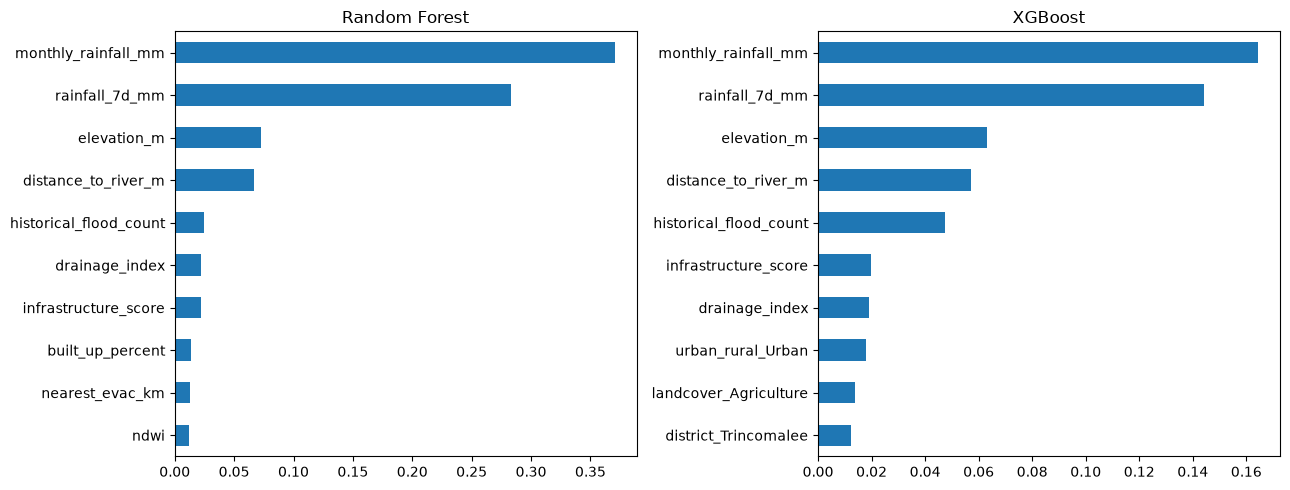

In [12]:
names = fitted["XGBoost"].named_steps["pre"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, n in zip(ax, ["Random Forest", "XGBoost"]):
    imp = pd.Series(fitted[n].named_steps["clf"].feature_importances_, index=names).nlargest(10)
    imp[::-1].plot.barh(ax=a, title=n)
plt.tight_layout(); plt.show()

## 9. Single sample inference

In [13]:
best = fitted["Stacking"]
prob = best.predict_proba(X_new)[0, 1]
print(X_new.T.to_string())
print(f"\nFlood probability: {prob:.3f}")
print("Prediction:", "Flood" if prob >= 0.5 else "No flood", "| Actual:", "Flood" if y_new.iloc[0] else "No flood")

                                   6868
district                     Batticaloa
latitude                       8.002435
longitude                      80.18234
elevation_m                          72
distance_to_river_m              1702.4
landcover                   Agriculture
soil_type                         Silty
water_supply                  Municipal
electricity                        Grid
road_quality                       Fair
population_density_per_km2          238
built_up_percent                   37.9
urban_rural                       Rural
rainfall_7d_mm                     25.5
monthly_rainfall_mm               209.6
drainage_index                    0.059
ndvi                             -0.229
ndwi                             -0.006
water_presence_flag            Unlikely
historical_flood_count                0
infrastructure_score                 65
nearest_hospital_km                0.18
nearest_evac_km                   14.78

Flood probability: 0.017
Prediction: No

## 10. Export model

In [14]:
final = Pipeline([("pre", pre), ("clf", models["Stacking"])]).fit(X_rest, y_rest)
pickle.dump(final, open("model.pkl", "wb"))